# Benchmark del calor 1D en la convencion del paper

Se compara, sobre el mismo problema y los mismos datos que el paper base (Shin et al., 2024, Sec. 5.1):

1. lo que **reporta el paper**: error relativo $L^2$ menor que $0.01$ en entrenamiento y en prueba, y su Figura 3 (el
   multiplicador $e^{-t\,a(\xi)}$ aprendido);
2. un **FNO** de la libreria `neuraloperator` (version 2.0.0), solo el FNO;
3. el **PDNO** con simbolos parabolicos en la configuracion lineal de `06_pdno_calor_1d.ipynb` ($d=1$, sin $W$ ni sesgos,
   $\sigma=$ identidad, $P=Q=$ identidad, $L=1$): $u(t)=e^{-t\,a_{\text{par}}(D)}u_0$.

El problema es el operador solucion $u_0\mapsto u(t)$ de $u_t=c\,u_{xx}$ en $\mathbb T=[0,1)$ con $c=0.05$:

$$u(t,x)=\sum_{\xi\in\mathbb Z}e^{-4\pi^2c\,\xi^2t}\,\hat u_0(\xi)\,e^{2\pi i x\xi},\qquad
u_0\sim\mathcal N\big(0,\;7^4(-\Delta+7^2)^{-2.5}\big).$$

PDNO y FNO se entrenan con **la misma perdida, el mismo optimizador y el mismo early stopping**: la unica diferencia es
la arquitectura (el PDNO suma ademas $\mathcal L_{\text{par}}$ y $\mathcal L_{\text{class}}$ sobre su simbolo, como en 06).

# Setup
- **Datos:** los GRF del paper en la malla de $1024$ puntos, $100$ condiciones iniciales de entrenamiento en `TRAIN_TIMES`
  y $20$ de prueba en `TEST_TIMES`. El paper entrena con las $100$ y sin validacion; aqui, como en 06, la particion es
  **por condicion inicial**: $80$ para entrenar y $20$ para validar (early stopping y seleccion), asi que los modelos ven
  $80$ $u_0$, no $100$.
- **Precision: todo el notebook en float32** (PDNO, FNO, datos y evaluacion). La capa espectral de `neuraloperator`
  crea sus pesos y su buffer de salida en `complex64`, asi que el FNO no puede correr en float64 sin parchear la
  libreria; para que la precision y los tiempos sean comparables, el PDNO tambien va en float32. Los campos exactos se
  generan en float64 (numpy) y se pasan a float32 antes de que los vea cualquier modelo. La subseccion 10.1 (opcional)
  reentrena el PDNO elegido en float64 y compara su error de prueba con el de float32.
- **Entrenamiento:** `OperatorTrainingConfig` con sus valores por defecto salvo la paciencia ($60$ epocas): AdamW,
  $\text{lr}=10^{-3}$ con decaimiento exponencial hasta $10^{-5}$, lotes de $20$ pares $(u_0,t)$, hasta $300$ epocas,
  recorte del gradiente en $1$ y early stopping sobre la validacion, restaurando la mejor epoca.
  - PDNO: `train_operator`, como en 06 (perdida total $L^2$ relativa $+\,\mathcal L_{\text{par}}+\mathcal L_{\text{class}}$,
    $C_\alpha$ de los datos).
  - FNO: `train_baseline`, el mismo esquema sin los terminos del simbolo (early stopping sobre la $L^2$ relativa de
    validacion), weight decay $0$. No se usa el `Trainer` de la libreria.
- **Barridos y seleccion** (menor $L^2$ relativa de validacion en los dos):
  - PDNO: el `SWEEP` de 02 y 06 sobre la MLP del simbolo ($30$ corridas).
  - FNO: `n_modes` $\in\{8,16,32,64,128\}\times$ `hidden_channels` $\in\{32,64\}\times$ `n_layers` $\in\{2,4\}$
    ($20$ corridas). En 1D la libreria conserva los modos $|k|\le$ `n_modes`$/2$: con $128$ el FNO ve la misma
    ventana $|k|\le64$ que las filas espectrales del PDNO.

La celda de parametros reune todo lo configurable.

In [1]:
import time
from dataclasses import replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from parabolic_symbol.symbols.heat import HeatSymbol
from parabolic_symbol.symbols.parabolic_mlp_symbol import ParabolicMLPSymbol
from parabolic_symbol.verification.parabolicity import ParabolicityVerifier
from parabolic_symbol.verification.symbol_class import SymbolClassVerifier
from parabolic_symbol.data.fields import field_datasets, resample_fields
from parabolic_symbol.data.grf import TEST_TIMES, TRAIN_TIMES, grf_variance
from parabolic_symbol.data.grids import k_grid
from parabolic_symbol.operators.config import PDNOConfig
from parabolic_symbol.operators.fno_baseline import FNOConfig
from parabolic_symbol.operators.pdno import PDNO, EffectiveSymbol
from parabolic_symbol.learning.baseline_training import (
    fno_sweep_table,
    load_fno_model,
    run_fno_sweep,
    save_fno_model,
)
from parabolic_symbol.learning.estimation import (
    estimate_bounds,
    estimate_class_constants,
    estimate_symbol,
    oracle_class_constants,
    symbol_values,
)
from parabolic_symbol.learning.evaluation import symbol_report
from parabolic_symbol.learning.experiment import CERT_LAM, SWEEP, SWEEP_COLS, class_C_table, relative_symbol_error
from parabolic_symbol.learning.operator_evaluation import field_errors
from parabolic_symbol.learning.operator_sweep import operator_sweep_table, run_operator_sweep
from parabolic_symbol.learning.sweep import best_run
from parabolic_symbol.learning.operator_training import (
    OperatorTrainingConfig,
    load_operator_model,
    save_operator_model,
    train_operator,
)
from parabolic_symbol.utils import default_device

np.set_printoptions(precision=4, suppress=True)

In [2]:
# ---------------------------------------------------------------- parametros
# Precision y device: float32 en todo el notebook (ver el Setup).
DEVICE = default_device()
DTYPE = torch.float32

# Datos en la convencion del paper (Sec. 5.1), llevada a [0, 2 pi) con x = 2 pi y (seccion 1).
PAPER_DIFFUSIVITY = 0.05                      # c del paper, en T = [0, 1)
DIFFUSIVITY = 4 * np.pi**2 * PAPER_DIFFUSIVITY   # a(k) = 4 pi^2 * 0.05 |k|^2 ~ 1.97 |k|^2
FREQ_SCALE = 4 * np.pi**2                     # autovalores de -Delta en [0, 1): 4 pi^2 xi^2
AMPLITUDE = np.sqrt(2 * np.pi)                # autofunciones e^{2 pi i x xi} de norma 1 en [0, 1)
REFERENCE = HeatSymbol(n=1, diffusivity=DIFFUSIVITY)
M = 2.0                        # orden del simbolo aprendido
RESOLUTION = 1024
K_CAP = 64                     # filas espectrales |k| <= k_cap para (c, C) y C_alpha; k_max = k_cap
SEED = 0                       # 100 u0 de entrenamiento (TRAIN_TIMES) y 20 de prueba (TEST_TIMES)
VAL_FRACTION = 0.2             # fraccion de las u0 de entrenamiento que va a validacion
DELTA = 0.1                    # margen de la banda (c, C)
ESTIMATE_TOL = 1e-10           # filtro de senal de estimate_symbol
PAPER_TOL = 0.01               # el paper reporta L2 relativa < 0.01 en entrenamiento y prueba

# Extrapolacion temporal: t en (0.95, 3], con las u0 de prueba; solo se reporta.
EXTRAPOLATION_TIMES = np.round(np.linspace(1.0, 3.0, 21), 10)

# PDNO: configuracion lineal, como en 06. La MLP del simbolo y el weight decay salen del barrido (SWEEP).
ARCH = dict(width=1, use_W=False, bias=False, activation="identity", lift="identity", project="identity")
N_LAYERS = 1                   # L
LEARN_TAU = False              # tau fijo en 1/L
MODEL_SEED = 0

# Entrenamiento: valores por defecto de OperatorTrainingConfig salvo patience=60, con C_alpha de los datos.
TRAIN_CONFIG = OperatorTrainingConfig(k_max=K_CAP, class_C_source="data", patience=60)
OMEGA = TRAIN_CONFIG.omega
CLASS_MARGIN = TRAIN_CONFIG.class_margin

# FNO: mismo esquema de entrenamiento (lr, decaimiento, lote, epocas, paciencia, semilla), weight decay 0.
# Los campos del simbolo de TRAIN_CONFIG (omega, lambdas, C_alpha, ...) no se usan.
FNO_TRAIN_CONFIG = replace(TRAIN_CONFIG, weight_decay=0.0)
FNO_BASE = FNOConfig(n_modes=16, hidden_channels=32, n_layers=2, positional_embedding="grid", seed=MODEL_SEED)
FNO_SWEEP = dict(n_modes=(8, 16, 32, 64, 128), hidden_channels=(32, 64), n_layers=(2, 4))

# Evaluacion.
EVAL_RESOLUTIONS = (256, 512, 1024, 2048)
SEMIGROUP_PAIRS = [            # (t, s): S(t + s) u0 frente a S(t) S(s) u0
    (0.05, 0.05), (0.1, 0.25), (0.25, 0.5), (0.5, 0.45), (0.3, 0.7),   # t, s y t + s en el rango
    (0.5, 0.5), (0.95, 0.95), (1.0, 0.5), (1.5, 1.5),                   # t + s (y a veces t, s) fuera
]
FIG3_XI = np.linspace(-12.0, 12.0, 481)       # xi continuo, como la Figura 3 del paper
FIG3_T = np.linspace(0.05, 1.0, 191)
RETRAIN_FLOAT64 = True         # subseccion 10.1: reentrenar el PDNO elegido en float64

RESULTS = Path("../results/10_benchmark_calor_1d")   # tablas (CSV) y figuras (PNG)
RESULTS.mkdir(parents=True, exist_ok=True)
print(f"device = {DEVICE}  |  dtype = {DTYPE}")
print(f"a(k) = {DIFFUSIVITY:.6f} |k|^2  |  freq_scale = {FREQ_SCALE:.6f}  |  amplitude = {AMPLITUDE:.6f}")

device = cuda  |  dtype = torch.float32
a(k) = 1.973921 |k|^2  |  freq_scale = 39.478418  |  amplitude = 2.506628


## 1. Datos en la convencion del paper

El repo trabaja en $[0,2\pi)$ con $u(x)=\sum_k\hat u(k)e^{ikx}$, $a(k)=|k|^2$ y $u_0\sim\mathcal N(0,7^4(-\Delta+7^2)^{-2.5})$. El paper trabaja en $[0,1)$. Con el cambio $x=2\pi y$ y $k=\xi$:

| | paper, $y\in[0,1)$ | repo, $x\in[0,2\pi)$ | en el notebook |
|---|---|---|---|
| simbolo | $4\pi^2c\,\xi^2$, $c=0.05$ | `HeatSymbol(diffusivity=D)`: $D\,|k|^2$ | $D=4\pi^2\cdot0.05\approx1.97$ ($m=2$) |
| autovalores de $-\Delta$ | $4\pi^2\xi^2$ | `freq_scale`$\cdot|k|^2$ | `freq_scale` $=4\pi^2$ |
| covarianza | $\sigma_\xi^2=7^4(4\pi^2\xi^2+49)^{-2.5}$ | $\sigma_k^2=7^4($`freq_scale`$\,k^2+49)^{-2.5}$ | la misma |
| $\hat u_0$ | $\sigma_\xi\,\zeta_\xi$ ($e^{2\pi i y\xi}$ de norma $1$) | `amplitude`$\cdot\sigma_k\zeta_k/\sqrt{2\pi}$ | `amplitude` $=\sqrt{2\pi}$ |

con $\zeta$ normal compleja estandar. Asi $u_{\text{repo}}(2\pi y)=u_{\text{paper}}(y)$: es **el mismo problema**, con las mismas
funciones evaluadas en los mismos $1024$ puntos $y_j=j/1024$. La $L^2$ relativa es un cociente de normas discretas en la
misma malla, asi que no cambia con el reescalamiento. Los tiempos son los mismos (`TRAIN_TIMES`, `TEST_TIMES`).

Con la misma semilla que 06, el ruido $\zeta_k$ es el mismo: solo cambian la covarianza por modo y el simbolo.

La celda comprueba la tabla (simbolo y covarianza contra las formulas del paper) y compara la varianza empirica de
$\hat u_0(\xi)$ sobre las $120$ condiciones iniciales con $\sigma_\xi^2$ del paper (con $120$ muestras el cociente
fluctua alrededor de $1$ en un $\sim10\%$).

In [3]:
ds64 = field_datasets(
    REFERENCE, RESOLUTION, SEED, k_cap=K_CAP, val_fraction=VAL_FRACTION,
    extrapolation_times=EXTRAPOLATION_TIMES, freq_scale=FREQ_SCALE, amplitude=AMPLITUDE,
)
ds = ds64.to("cpu", DTYPE)     # lo que ven los modelos y la evaluacion: float32
k_max = K_CAP

conjuntos = {"entrenamiento": ds.train, "validacion": ds.val, "prueba": ds.test, "extrapolacion": ds.extrapolation}
assert np.allclose(ds.train.t, TRAIN_TIMES) and np.allclose(ds.test.t, TEST_TIMES)

# Disjuntos: entrenamiento / validacion por indice; prueba frente a ambos por distancia entre campos u0.
assert set(ds.train.ic).isdisjoint(ds.val.ic)
vistas = torch.cat([ds.train.u0, ds.val.u0])
distancia = torch.cdist(ds.test.u0, vistas).min() / torch.linalg.vector_norm(ds.test.u0, dim=1).min()
assert distancia > 0

# Convencion del paper: simbolo y covarianza en xi = k.
xi = np.arange(0, 9)
a_paper = 4 * np.pi**2 * PAPER_DIFFUSIVITY * xi**2
sigma2_paper = 7.0**4 * (4 * np.pi**2 * xi**2 + 7.0**2) ** (-2.5)
assert np.allclose(symbol_values(REFERENCE, xi[:, None]), a_paper)
assert np.allclose(AMPLITUDE**2 * grf_variance(xi, freq_scale=FREQ_SCALE) / (2 * np.pi), sigma2_paper)

# Varianza empirica de u0_hat(xi) (orden de np.fft: xi >= 0 en las primeras posiciones).
u0_hat = np.concatenate([ds64.grf_train.u0_hat, ds64.grf_test.u0_hat])
convencion = pd.DataFrame({
    "a(xi) paper": a_paper,
    "a(k) repo": symbol_values(REFERENCE, xi[:, None]),
    "sigma2 paper": sigma2_paper,
    "E|u0_hat|^2 empirica": np.mean(np.abs(u0_hat[:, xi]) ** 2, axis=0),
}, index=pd.Index(xi, name="xi = k"))
convencion["empirica / paper"] = convencion["E|u0_hat|^2 empirica"] / convencion["sigma2 paper"]
convencion.to_csv(RESULTS / "convencion.csv")
display(convencion)

print()
print(f"k_max = k_cap = {k_max}")
for nombre, data in conjuntos.items():
    print(f"{nombre:14s}: {data.n_ic:3d} condiciones iniciales x {data.n_times:2d} tiempos = {data.n_pairs:4d} pares")
print(f"prueba: min ||u0_prueba - u0_vista|| / ||u0_prueba|| = {float(distancia):.3f}  (> 0: disjunta)")
print(f"filas espectrales para la banda y las C_alpha: {ds.rows_train['k'].shape[0]:,} "
      f"(solo las {ds.train.n_ic} u0 de entrenamiento)")
print(f"dtype de los campos: {ds.train.u.dtype}, de las filas: {ds.rows_train['u0'].dtype}")

tabla_datos = pd.DataFrame([
    {"conjunto": nombre, "condiciones_iniciales": data.n_ic, "tiempos": data.n_times,
     "pares": data.n_pairs, "t_min": float(data.t.min()), "t_max": float(data.t.max())}
    for nombre, data in conjuntos.items()
]).set_index("conjunto")
tabla_datos.to_csv(RESULTS / "datos.csv")
display(tabla_datos)

ENTRENAMIENTO
100 condiciones iniciales x 10 tiempos, resolucion 1024: 1290 pares (k, t) con |k|_inf <= 64 -> 129,000 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]
PRUEBA
20 condiciones iniciales x 20 tiempos, resolucion 1024: 2580 pares (k, t) con |k|_inf <= 64 -> 51,600 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]
CAMPOS (condicion inicial x tiempo)
  train        : 80 u0 x 10 tiempos = 800 pares, malla (1024,)
  val          : 20 u0 x 10 tiempos = 200 pares, malla (1024,)
  test         : 20 u0 x 20 tiempos = 400 pares, malla (1024,)
  extrapolation: 20 u0 x 21 tiempos = 420 pares, malla (1024,)


,a(xi) paper,a(k) repo,sigma2 paper,E|u0_hat|^2 empirica,empirica / paper
xi = k,,,,,
0,0.000000,0.000000,0.142857,0.133724,0.936065
1,1.973921,1.973921,0.032606,0.031589,0.968805
2,7.895684,7.895684,0.003899,0.004080,1.046455
3,17.765288,17.765288,0.000730,0.000721,0.987231
4,31.582734,31.582734,0.000199,0.000203,1.024162
5,49.348022,49.348022,0.000070,0.000064,0.923964
6,71.061152,71.061152,0.000029,0.000029,0.994792
7,96.722123,96.722123,0.000014,0.000011,0.805573
8,126.330936,126.330936,0.000007,0.000008,1.137729



k_max = k_cap = 64
entrenamiento :  80 condiciones iniciales x 10 tiempos =  800 pares
validacion    :  20 condiciones iniciales x 10 tiempos =  200 pares
prueba        :  20 condiciones iniciales x 20 tiempos =  400 pares
extrapolacion :  20 condiciones iniciales x 21 tiempos =  420 pares
prueba: min ||u0_prueba - u0_vista|| / ||u0_prueba|| = 0.364  (> 0: disjunta)
filas espectrales para la banda y las C_alpha: 103,200 (solo las 80 u0 de entrenamiento)
dtype de los campos: torch.float32, de las filas: torch.complex64


,condiciones_iniciales,tiempos,pares,t_min,t_max
conjunto,,,,,
entrenamiento,80,10,800,0.05,0.95
validacion,20,10,200,0.05,0.95
prueba,20,20,400,0.05,1.00
extrapolacion,20,21,420,1.00,3.00


**Condiciones iniciales y evolucion.** Dos $u_0$ de entrenamiento y la solucion exacta en algunos tiempos de
`TRAIN_TIMES`, de oscuro a claro con $t$ creciente, en la variable del paper $y=x/2\pi\in[0,1)$.

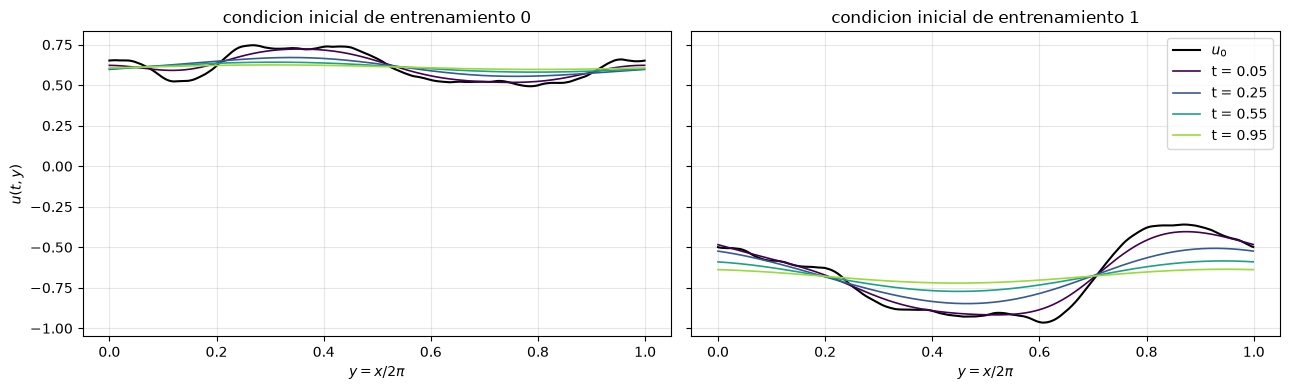

In [4]:
y = np.arange(RESOLUTION) / RESOLUTION              # y = x / (2 pi), la malla del paper
idx_t = [0, 2, 5, 9]                                 # t = 0.05, 0.25, 0.55, 0.95
colores = plt.cm.viridis(np.linspace(0, 0.85, len(idx_t)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, i in zip(axes, (0, 1)):
    ax.plot(y, ds.train.u0[i].numpy(), "k-", lw=1.5, label=r"$u_0$")
    for j, color in zip(idx_t, colores):
        ax.plot(y, ds.train.u[i, j].numpy(), color=color, lw=1.2, label=f"t = {float(ds.train.t[j]):.2f}")
    ax.set_xlabel(r"$y = x / 2\pi$")
    ax.set_title(f"condicion inicial de entrenamiento {ds.train.ic[i]}")
    ax.grid(alpha=0.3)
axes[0].set_ylabel(r"$u(t, y)$")
axes[1].legend()
plt.tight_layout()
fig.savefig(RESULTS / "condiciones_iniciales.png", dpi=150)
plt.show()

## 2. Banda $(c,C)$, $\kappa$ y constantes $C_\alpha$

Como en 06, sobre `ds.rows_train` (las filas espectrales con $|k|\le k_{\text{cap}}$ de las $u_0$ de entrenamiento, aqui en
float32). `estimate_symbol` ajusta $\hat a(k)$, `estimate_bounds` da $(c,C)$ con $\delta=0.1$ y $\kappa=$
`theoretical_kappa()`. Las $C_\alpha$ salen del mismo $\hat a$ con margen $1.5$; las del oraculo son solo comparacion.

La banda **no es la de 06**, y es lo esperado: ahora $a(k)/\langle k\rangle^2=1.97\,k^2/(1+k^2)$ va de $\approx0.99$ en
$k=1$ a $\approx1.97$, en lugar de $[0.5,1)$.

In [5]:
k_est, a_hat = estimate_symbol(ds.rows_train, tol=ESTIMATE_TOL)
bounds = estimate_bounds(k_est, a_hat, m=M, delta=DELTA)
probe = ParabolicMLPSymbol(n=1, m=M, c=bounds.c, C=bounds.C, device="cpu", dtype=DTYPE)
kappa = probe.theoretical_kappa(OMEGA)

class_C, class_C_counts = estimate_class_constants(
    k_est, a_hat, M, rho=probe.rho, margin=CLASS_MARGIN, return_counts=True
)
class_C_oracle = oracle_class_constants(REFERENCE, k_max, margin=CLASS_MARGIN, rho=probe.rho)

k_band = np.arange(1, k_max + 1)
h_exacta = symbol_values(REFERENCE, k_band[:, None]) / (1.0 + k_band**2) ** (M / 2)
print(f"(c, C) de los datos = ({bounds.c:.4f}, {bounds.C:.4f})   m = {M:g}, ventana: {bounds.window}")
print(f"a(k) / <k>^m exacto en 1 <= |k| <= {k_max}: [{h_exacta.min():.4f}, {h_exacta.max():.4f}]")
print(f"kappa teorico       = {kappa:.4f}   (omega = {OMEGA:g})")

pd.Series({"c": bounds.c, "C": bounds.C, "m": M, "kappa_teorico": kappa},
          name="valor").to_csv(RESULTS / "constantes.csv")
tabla_C = class_C_table(class_C, class_C_oracle, class_C_counts, CLASS_MARGIN)
tabla_C.to_csv(RESULTS / "class_C.csv")
display(tabla_C)

estimate_symbol: 9,760 de 103,200 pares (k, t) con senal (tol=1e-10); 31 de 129 k de entrenamiento
  ventana usada: 31 k, |k|_inf <= 15, |k| in [0, 15]
(c, C) de los datos = (0.8883, 2.1617)   m = 2, ventana: 30 k, |k|_inf <= 15, |k| in [1, 15]
a(k) / <k>^m exacto en 1 <= |k| <= 64: [0.9870, 1.9734]
kappa teorico       = 2.0000   (omega = 1)


,C_alpha datos (x1.5),C_alpha oraculo (x1.5),k_usados
alpha,,,
"(0,)",2.947780,2.960159,31
"(1,)",6.620732,6.620732,30
"(2,)",5.921789,5.921763,29


## 3. Barridos y seleccion

### 3.1 PDNO

El mismo barrido que 06 (`SWEEP`): $\{2,3,4\}$ capas ocultas $\times$ $\{32,64,128\}$ neuronas en la MLP del simbolo,
dropout $0.2$ en `none` o `middle` y weight decay $\{0,10^{-4}\}$, $30$ corridas con las mismas semillas. La arquitectura
del PDNO (`ARCH`, `N_LAYERS`, `LEARN_TAU`) queda fija. Early stopping sobre la perdida total de validacion; se elige la
corrida de **menor $L^2$ relativa de validacion** (`best_run`).

In [6]:
base_model = PDNOConfig(
    n=1, m=M, c=bounds.c, C=bounds.C, n_layers=N_LAYERS, learn_tau=LEARN_TAU, seed=MODEL_SEED, **ARCH
)
assert base_model.is_semigroup, "este notebook usa la configuracion lineal"

runs_pdno = run_operator_sweep(
    ds.train, ds.val, base_model, TRAIN_CONFIG, rows=ds.rows_train, device=DEVICE, dtype=DTYPE, **SWEEP
)

tabla_pdno = operator_sweep_table(runs_pdno)
tabla_pdno.to_csv(RESULTS / "barrido_pdno.csv", index=False)
print(f"{len(tabla_pdno)} corridas, {tabla_pdno['segundos'].sum() / 60:.1f} min de entrenamiento en total")
display(tabla_pdno[SWEEP_COLS].sort_values("val_rel_l2").reset_index(drop=True))

[  1/30] 2x32  drop[-] wd=0e+00 | rel_l2=0.0003 |  74.2s
[  2/30] 2x32  drop[-] wd=1e-04 | rel_l2=0.0003 |  75.2s
[  3/30] 2x64  drop[-] wd=0e+00 | rel_l2=0.0002 |  69.6s
[  4/30] 2x64  drop[-] wd=1e-04 | rel_l2=0.0002 |  69.0s
[  5/30] 2x128 drop[-] wd=0e+00 | rel_l2=0.0001 |  72.0s
[  6/30] 2x128 drop[-] wd=1e-04 | rel_l2=0.0001 |  74.6s
[  7/30] 3x32  drop[-] wd=0e+00 | rel_l2=0.0008 |  73.4s
[  8/30] 3x32  drop[-] wd=1e-04 | rel_l2=0.0008 |  72.4s
[  9/30] 3x32  drop[1] wd=0e+00 | rel_l2=0.0242 |  75.3s
[ 10/30] 3x32  drop[1] wd=1e-04 | rel_l2=0.0242 |  76.4s
[ 11/30] 3x64  drop[-] wd=0e+00 | rel_l2=0.0001 |  73.6s
[ 12/30] 3x64  drop[-] wd=1e-04 | rel_l2=0.0001 |  74.4s
[ 13/30] 3x64  drop[1] wd=0e+00 | rel_l2=0.0234 |  76.1s
[ 14/30] 3x64  drop[1] wd=1e-04 | rel_l2=0.0235 |  78.7s
[ 15/30] 3x128 drop[-] wd=0e+00 | rel_l2=0.0001 |  33.7s
[ 16/30] 3x128 drop[-] wd=1e-04 | rel_l2=0.0001 |  20.8s
[ 17/30] 3x128 drop[1] wd=0e+00 | rel_l2=0.0241 |  80.1s
[ 18/30] 3x128 drop[1] wd=1e-04

,capas,ancho,dropout,weight_decay,val_rel_l2,val_total,val_par_max_ratio
0,4,128,OFF,0.0000,0.000056,0.000056,0.768448
1,4,128,OFF,0.0001,0.000060,0.000060,0.768448
2,3,64,OFF,0.0000,0.000068,0.000068,0.768448
3,3,64,OFF,0.0001,0.000068,0.000068,0.768448
4,3,128,OFF,0.0000,0.000073,0.000073,0.768448
5,4,64,OFF,0.0000,0.000082,0.000082,0.768448
6,4,64,OFF,0.0001,0.000085,0.000085,0.768448
7,3,128,OFF,0.0001,0.000091,0.000091,0.768448
8,2,128,OFF,0.0000,0.000092,0.000092,0.768448
9,2,128,OFF,0.0001,0.000092,0.000092,0.768448


In [7]:
best_pdno = best_run(runs_pdno)
model_pdno, result_pdno = best_pdno.model, best_pdno.result

print(f"kappa = theoretical_kappa() = {model_pdno.theoretical_kappa(OMEGA):.4f}")
print(f"arquitectura elegida    = {best_pdno.n_layers} capas x {best_pdno.width} neuronas (MLP del simbolo)")
print(f"dropout                 = {best_pdno.dropout_desc}")
print(f"weight decay            = {best_pdno.weight_decay:g}  (Linear ocultas interiores)")
print(f"early stopping          = mejor epoca {best_pdno.best_epoch} de {best_pdno.epochs_run} epocas; "
      f"se detuvo antes del final: {best_pdno.stopped_early}")
print(f"C_alpha de train_operator = las de class_C.csv: {result_pdno.class_C == class_C}")
print()
print("metricas de validacion en la mejor epoca:")
print(f"  total             = {best_pdno.val_total:.4e}")
print(f"  rel_l2            = {best_pdno.val_rel_l2:.4f}")
print(f"  parabolicidad     = {best_pdno.val_parabolicity:.4e}   (0 => ningun punto viola la cota)")
print(f"  clase             = {best_pdno.val_class:.4e}")
print(f"  peor ratio        = {best_pdno.val_par_max_ratio:.4f}")

kappa = theoretical_kappa() = 2.0000
arquitectura elegida    = 4 capas x 128 neuronas (MLP del simbolo)
dropout                 = OFF
weight decay            = 0  (Linear ocultas interiores)
early stopping          = mejor epoca 279 de 300 epocas; se detuvo antes del final: False
C_alpha de train_operator = las de class_C.csv: True

metricas de validacion en la mejor epoca:
  total             = 5.5753e-05
  rel_l2            = 0.0001
  parabolicidad     = 0.0000e+00   (0 => ningun punto viola la cota)
  clase             = 0.0000e+00
  peor ratio        = 0.7684


### 3.2 FNO

`FNOBaseline` envuelve el `FNO` de `neuraloperator` 2.0.0 con la interfaz del PDNO, `forward(u0, t)`:

- **Entrada:** dos canales sobre la malla, $u_0(x)$ y $t$ constante; el embedding de posicion `"grid"` de la libreria
  agrega $y\in[0,1)$ (`linspace(0, 1, R + 1)[:-1]`, periodico y recalculado en cada resolucion). **Salida:** $u(t)$, un
  canal. Sin `domain_padding`: el problema es periodico y la FFT tambien. El resto, valores por defecto del `FNO`.
- **Modos:** en 1D con datos reales la libreria conserva `n_modes // 2 + 1` modos de rfft, es decir $|k|\le$ `n_modes`$/2$.
- El embedding de posicion rompe la equivariancia por traslacion que tiene el problema; se usa porque es el valor por
  defecto del FNO.

Barrido: `n_modes` $\in\{8,16,32,64,128\}$ $\times$ `hidden_channels` $\in\{32,64\}$ $\times$ `n_layers` $\in\{2,4\}$,
$20$ corridas con las mismas semillas de modelo y de entrenamiento. Cada una es `train_baseline` con `FNO_TRAIN_CONFIG`;
se elige la de **menor $L^2$ relativa de validacion**.

In [8]:
runs_fno = run_fno_sweep(ds.train, ds.val, FNO_BASE, FNO_TRAIN_CONFIG, device=DEVICE, **FNO_SWEEP)

tabla_fno = fno_sweep_table(runs_fno)
tabla_fno.to_csv(RESULTS / "barrido_fno.csv", index=False)
print(f"{len(tabla_fno)} corridas, {tabla_fno['segundos'].sum() / 60:.1f} min de entrenamiento en total")
display(tabla_fno.sort_values("val_rel_l2").reset_index(drop=True))

# Por eje del barrido: la mejor L2 relativa de validacion.
for eje in ("n_modes", "hidden_channels", "capas"):
    display(tabla_fno.groupby(eje).agg(corridas=("val_rel_l2", "size"), mejor_val_rel_l2=("val_rel_l2", "min")))

[  1/20] n_modes=8   hidden=32  capas=2 | rel_l2=0.1360 |  56.7s
[  2/20] n_modes=8   hidden=32  capas=4 | rel_l2=0.0677 |  61.0s
[  3/20] n_modes=8   hidden=64  capas=2 | rel_l2=0.0545 | 130.3s
[  4/20] n_modes=8   hidden=64  capas=4 | rel_l2=0.0770 |  84.2s
[  5/20] n_modes=16  hidden=32  capas=2 | rel_l2=0.1426 |  29.1s
[  6/20] n_modes=16  hidden=32  capas=4 | rel_l2=0.0688 |  57.3s
[  7/20] n_modes=16  hidden=64  capas=2 | rel_l2=0.0724 |  85.4s
[  8/20] n_modes=16  hidden=64  capas=4 | rel_l2=0.0278 | 201.0s
[  9/20] n_modes=32  hidden=32  capas=2 | rel_l2=0.1075 |  75.8s
[ 10/20] n_modes=32  hidden=32  capas=4 | rel_l2=0.1200 | 106.9s
[ 11/20] n_modes=32  hidden=64  capas=2 | rel_l2=0.0385 | 105.0s
[ 12/20] n_modes=32  hidden=64  capas=4 | rel_l2=0.0505 | 318.1s
[ 13/20] n_modes=64  hidden=32  capas=2 | rel_l2=0.0388 |  80.8s
[ 14/20] n_modes=64  hidden=32  capas=4 | rel_l2=0.0606 | 136.0s
[ 15/20] n_modes=64  hidden=64  capas=2 | rel_l2=0.0264 | 117.3s
[ 16/20] n_modes=64  hidd

,n_modes,k_max_fno,hidden_channels,capas,parametros,val_rel_l2,mejor_epoca,epocas,segundos
0,64,32,64,2,574721,0.026355,129,189,117.308610
1,16,8,64,4,345793,0.027766,132,192,201.032880
2,64,32,64,4,1132225,0.035841,130,190,206.538963
3,128,64,64,2,1099009,0.037838,106,166,107.645869
4,32,16,64,2,312577,0.038518,113,173,104.951746
5,64,32,32,2,144001,0.038788,185,245,80.759027
6,32,16,64,4,607937,0.050520,296,300,318.099650
7,8,4,64,2,115969,0.054504,158,218,130.268247
8,64,32,32,4,283489,0.060596,177,237,136.041921
9,8,4,32,4,54113,0.067663,49,109,61.042004


,corridas,mejor_val_rel_l2
n_modes,,
8,4,0.054504
16,4,0.027766
32,4,0.038518
64,4,0.026355
128,4,0.037838


,corridas,mejor_val_rel_l2
hidden_channels,,
32,10,0.038788
64,10,0.026355


,corridas,mejor_val_rel_l2
capas,,
2,10,0.026355
4,10,0.027766


In [9]:
best_fno = best_run(runs_fno)
model_fno, result_fno = best_fno.model, best_fno.result

print(f"arquitectura elegida    = n_modes {best_fno.n_modes} (|k| <= {best_fno.n_modes // 2}), "
      f"hidden_channels {best_fno.hidden_channels}, {best_fno.n_layers} capas")
print(f"parametros              = {best_fno.n_parameters:,} (reales; un peso complejo cuenta como dos)")
print(f"early stopping          = mejor epoca {best_fno.best_epoch} de {best_fno.epochs_run} epocas; "
      f"se detuvo antes del final: {best_fno.stopped_early}")
print(f"rel_l2 de validacion    = {best_fno.val_rel_l2:.4f}")

arquitectura elegida    = n_modes 64 (|k| <= 32), hidden_channels 64, 2 capas
parametros              = 574,721 (reales; un peso complejo cuenta como dos)
early stopping          = mejor epoca 129 de 189 epocas; se detuvo antes del final: True
rel_l2 de validacion    = 0.0264


### 3.3 Curvas de entrenamiento

Las dos corridas elegidas, por epoca, en entrenamiento y validacion y en escala log. La linea punteada marca la epoca
cuyos pesos restauro el early stopping. PDNO: perdida total y cada termino, como en 06. FNO: su unico termino, la $L^2$
relativa. Un termino que vale $0$ en todas las epocas no se puede dibujar en escala log y se indica en el panel.

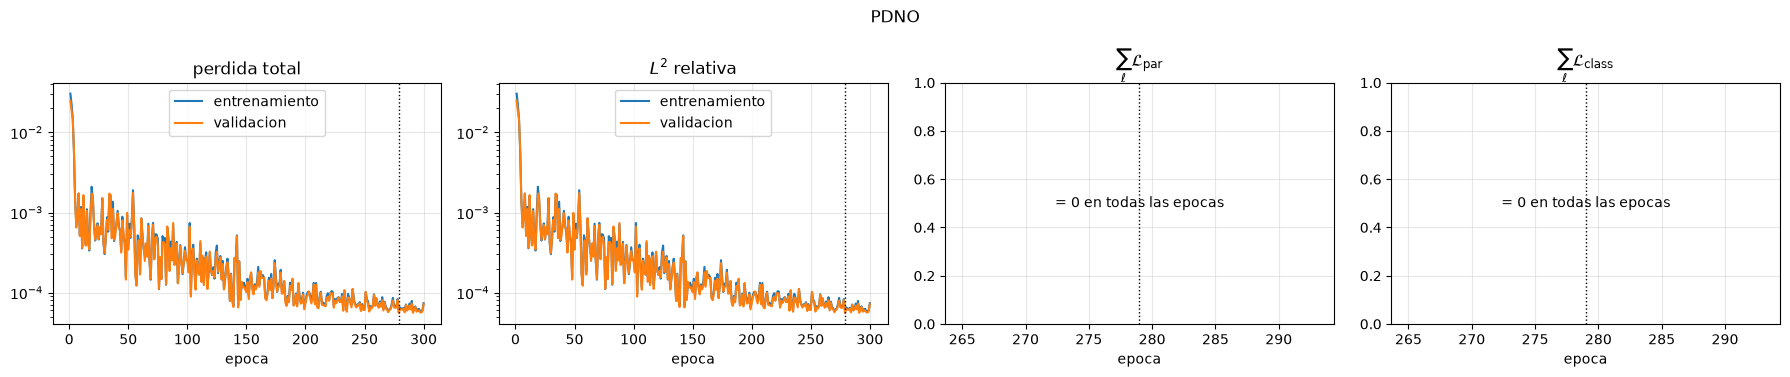

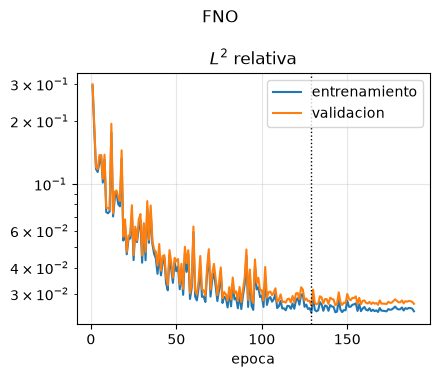

In [10]:
def curves_figure(result, paneles, titulo, nombre):
    history = result.history
    epochs = np.arange(1, len(history["train"]["total"]) + 1)
    fig, axes = plt.subplots(1, len(paneles), figsize=(4.5 * len(paneles), 3.8), squeeze=False)
    for ax, (key, sub) in zip(axes[0], paneles):
        curvas = {"entrenamiento": np.asarray(history["train"][key]),
                  "validacion": np.asarray(history["val"][key])}
        if all(np.all(v <= 0) for v in curvas.values()):
            ax.text(0.5, 0.5, "= 0 en todas las epocas", ha="center", va="center", transform=ax.transAxes)
        else:
            for etiqueta, valores in curvas.items():
                ax.semilogy(epochs, np.where(valores > 0, valores, np.nan), label=etiqueta)
            ax.legend()
        ax.axvline(result.best_epoch, color="k", ls=":", lw=1)
        ax.set_xlabel("epoca")
        ax.set_title(sub)
        ax.grid(alpha=0.3)
    fig.suptitle(titulo)
    plt.tight_layout()
    fig.savefig(RESULTS / nombre, dpi=150)
    plt.show()


curves_figure(result_pdno, [
    ("total", "perdida total"),
    ("rel_l2", r"$L^2$ relativa"),
    ("parabolicity", r"$\sum_\ell \mathcal{L}_{\mathrm{par}}$"),
    ("class", r"$\sum_\ell \mathcal{L}_{\mathrm{class}}$"),
], "PDNO", "perdida_pdno.png")
curves_figure(result_fno, [("rel_l2", r"$L^2$ relativa")], "FNO", "perdida_fno.png")

## 4. Comparacion con el paper

**$L^2$ relativa en entrenamiento y prueba.** El paper reporta un error relativo $L^2$ menor que $0.01$ en los dos
conjuntos. Aqui: entrenamiento = las $80$ $u_0$ de entrenamiento en `TRAIN_TIMES`; prueba = las $20$ $u_0$ de prueba en
`TEST_TIMES`. Media y maximo sobre todos los pares $(u_0,t)$; la media es la metrica comparable con el umbral.

In [11]:
models = {"PDNO": model_pdno, "FNO": model_fno}
err_train = {nombre: field_errors(m, ds.train) for nombre, m in models.items()}   # (n_ic, T)
err_test = {nombre: field_errors(m, ds.test) for nombre, m in models.items()}

filas = []
for nombre in models:
    for conjunto, err, data in (("entrenamiento", err_train[nombre], ds.train), ("prueba", err_test[nombre], ds.test)):
        filas.append({
            "modelo": nombre, "conjunto": conjunto, "condiciones_iniciales": data.n_ic, "tiempos": data.n_times,
            "rel_l2_media": err.mean(), "rel_l2_max": err.max(), "umbral_paper": PAPER_TOL,
            "media_bajo_umbral": err.mean() < PAPER_TOL,
        })
tabla_paper = pd.DataFrame(filas).set_index(["modelo", "conjunto"])
tabla_paper.to_csv(RESULTS / "comparacion_paper.csv")
print(f"paper (Shin et al., 2024, Sec. 5.1): L2 relativa < {PAPER_TOL} en entrenamiento y prueba")
display(tabla_paper)

paper (Shin et al., 2024, Sec. 5.1): L2 relativa < 0.01 en entrenamiento y prueba


condiciones_iniciales  tiempos  rel_l2_media  \
modelo conjunto                                                      
PDNO   entrenamiento                     80       10      0.000058   
       prueba                            20       20      0.000030   
FNO    entrenamiento                     80       10      0.024393   
       prueba                            20       20      0.019630   

                      rel_l2_max  umbral_paper  media_bajo_umbral  
modelo conjunto                                                    
PDNO   entrenamiento    0.002080          0.01               True  
       prueba           0.000909          0.01               True  
FNO    entrenamiento    0.197979          0.01              False  
       prueba           0.065025          0.01              False

**Replica de la Figura 3.** El multiplicador $e^{-t\,a(\xi)}$ exacto, con $a(\xi)=4\pi^2\cdot0.05\,\xi^2$, y el aprendido por el
PDNO, $e^{-t\,\bar a(\xi)}$, sobre $(\xi,t)\in[-12,12]\times[0.05,1]$, y su diferencia absoluta. $\xi$ es continuo, como en
el paper: el simbolo del PDNO se puede evaluar fuera de los enteros, pero solo los $\xi$ enteros (las lineas
verticales del panel de error) son modos del toro y los fijan los datos. Entre $\xi=0$ y $|\xi|=1$ no hay ningun modo: ahi
$\bar a(\xi)=\langle\xi\rangle^m\big(c+(C-c)\,\sigma(\cdot)\big)\ge c>0$, mientras que el exacto tiende a $0$, y solo en $\xi=0$ la
mascara de `ParabolicMLPSymbol` lo anula (la linea vertical en $\xi=0$). Esa diferencia no la ven ni los datos ni la
solucion. El FNO no tiene un multiplicador: no aparece aqui.

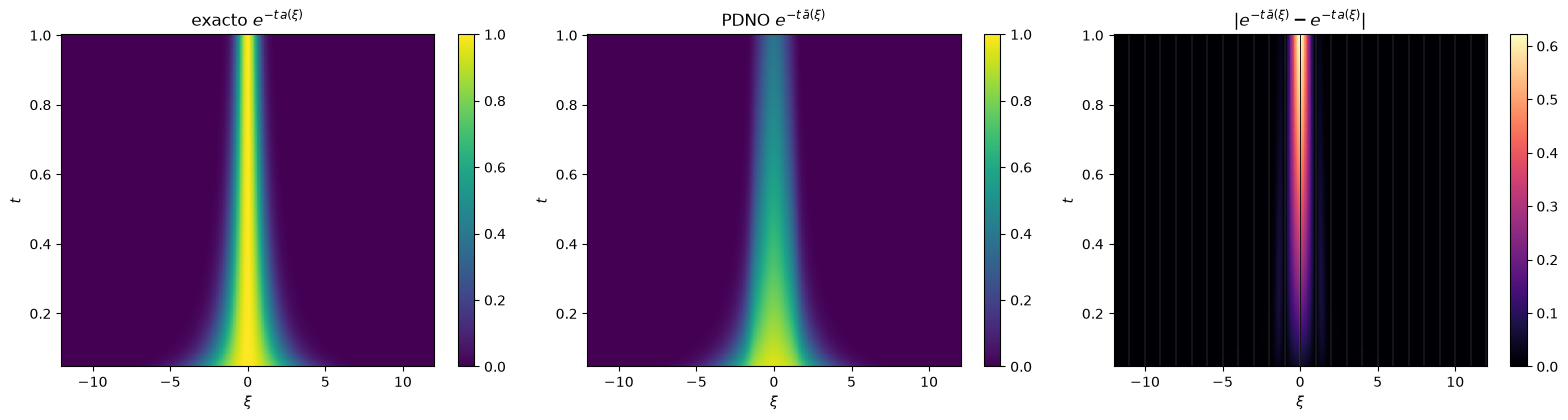

,valor
max |dif| (xi continuo),0.621893
max |dif| (xi entero),0.006680
media |dif| (xi continuo),0.019008


In [12]:
efectivo = EffectiveSymbol(model_pdno)
xi_grid, t_grid = np.meshgrid(FIG3_XI, FIG3_T)
mult_exacto = np.exp(-t_grid * symbol_values(REFERENCE, FIG3_XI[:, None])[None])
mult_pdno = np.exp(-t_grid * np.real(efectivo.evaluate_batch(FIG3_XI[:, None]))[None])
dif = np.abs(mult_pdno - mult_exacto)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
paneles = [(mult_exacto, r"exacto $e^{-t\,a(\xi)}$"), (mult_pdno, r"PDNO $e^{-t\,\bar a(\xi)}$")]
for ax, (valores, titulo) in zip(axes[:2], paneles):
    im = ax.pcolormesh(xi_grid, t_grid, valores, shading="auto", cmap="viridis", vmin=0, vmax=1)
    ax.set_title(titulo)
    fig.colorbar(im, ax=ax)
im = axes[2].pcolormesh(xi_grid, t_grid, dif, shading="auto", cmap="magma")
for entero in range(-12, 13):
    axes[2].axvline(entero, color="w", lw=0.3, alpha=0.4)
axes[2].set_title(r"$|e^{-t\,\bar a(\xi)} - e^{-t\,a(\xi)}|$")
fig.colorbar(im, ax=axes[2])
for ax in axes:
    ax.set_xlabel(r"$\xi$")
    ax.set_ylabel(r"$t$")
plt.tight_layout()
fig.savefig(RESULTS / "figura3.png", dpi=150)
plt.show()

enteros = np.isclose(FIG3_XI, np.round(FIG3_XI))
figura3 = pd.Series({
    "max |dif| (xi continuo)": dif.max(),
    "max |dif| (xi entero)": dif[:, enteros].max(),
    "media |dif| (xi continuo)": dif.mean(),
}, name="valor")
figura3.to_csv(RESULTS / "figura3.csv")
display(figura3.to_frame())

## 5. Prueba

Error relativo $L^2$ de cada condicion inicial de prueba y tiempo de `TEST_TIMES`, media y maximo por tiempo, para los
dos modelos en la misma tabla y la misma figura. Los tiempos de `TEST_TIMES` que no estan en `TRAIN_TIMES` (los
intermedios y $t=1$) no se vieron al entrenar: en la figura van con circulos y lineas grises.

PRUEBA -- 20 condiciones iniciales nuevas x 20 tiempos
  PDNO: error relativo L2 = 2.9974e-05  (medio; max 9.0850e-04)
  FNO: error relativo L2 = 1.9630e-02  (medio; max 6.5025e-02)


PDNO                 FNO                           
               media       max     media       max en_entrenamiento
t                                                                  
0.05    3.741828e-04  0.000909  0.013673  0.020220             True
0.10    1.312889e-04  0.000307  0.015663  0.028979            False
0.15    4.587990e-05  0.000106  0.014807  0.029100             True
0.20    1.795269e-05  0.000053  0.014635  0.037353            False
0.25    8.804624e-06  0.000028  0.015412  0.046361             True
0.30    5.325048e-06  0.000019  0.016644  0.053596            False
0.35    3.623597e-06  0.000015  0.017808  0.058894             True
0.40    2.626981e-06  0.000012  0.018801  0.062383            False
0.45    1.974759e-06  0.000009  0.019546  0.064278             True
0.50    1.514455e-06  0.000007  0.020071  0.065021            False
0.55    1.199402e-06  0.000005  0.020450  0.065025             True
0.60    9.427824e-07  0.000004  0.020772  0.064662            False
0.65    7.984240e-07  0.000003  0.021100  0.064123             True
0.70    6.501829e-07  0.000002  0.021475  0.063519            False
0.75    5.550459e-07  0.000002  0.021925  0.062875             True
0.80    4.993564e-07  0.000002  0.022475  0.062230            False
0.85    4.434916e-07  0.000001  0.023120  0.061597             True
0.90    4.288253e-07  0.000002  0.023852  0.061044            False
0.95    4.014865e-07  0.000002  0.024681  0.060653             True
1.00    3.816281e-07  0.000002  0.025700  0.063542            False
global  2.997372e-05  0.000909  0.019630  0.065025             None

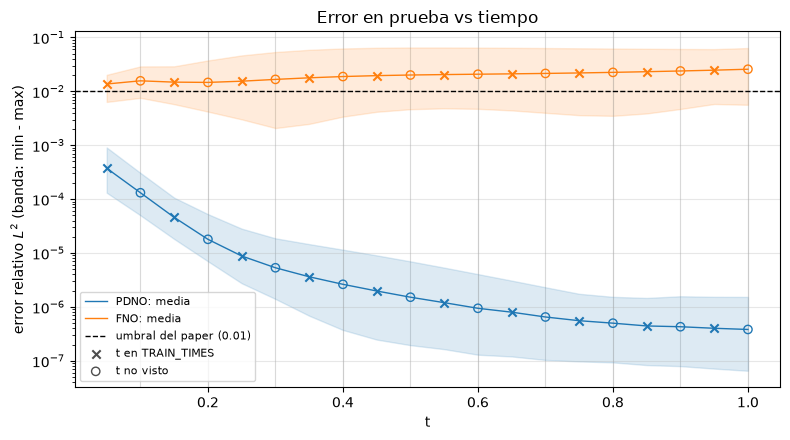

In [13]:
t_train = ds.train.t.numpy()
colores_modelo = {"PDNO": "C0", "FNO": "C1"}


def error_table(errs, t):
    # Media y maximo por tiempo de cada modelo, y el global; cada err tiene forma (n_ic, T).
    visto = np.isclose(t[:, None], t_train[None]).any(axis=1)
    columnas = {}
    for nombre, err in errs.items():
        columnas[(nombre, "media")] = np.append(err.mean(axis=0), err.mean())
        columnas[(nombre, "max")] = np.append(err.max(axis=0), err.max())
    tabla = pd.DataFrame(columnas, index=pd.Index([f"{x:.2f}" for x in t] + ["global"], name="t"))
    tabla[("", "en_entrenamiento")] = list(visto) + [None]
    return tabla


def error_figure(errs, t, titulo, nombre):
    # Media y banda min-max por tiempo de cada modelo; los tiempos no vistos, con circulos y lineas grises.
    visto = np.isclose(t[:, None], t_train[None]).any(axis=1)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for tiempo in t[~visto]:
        ax.axvline(tiempo, color="0.85", lw=0.8, zorder=0)
    for nombre_modelo, err in errs.items():
        color = colores_modelo[nombre_modelo]
        media = err.mean(axis=0)
        ax.semilogy(t, media, "-", color=color, lw=1, label=f"{nombre_modelo}: media")
        ax.fill_between(t, err.min(axis=0), err.max(axis=0), color=color, alpha=0.15)
        ax.scatter(t[visto], media[visto], color=color, marker="x", zorder=3)
        ax.scatter(t[~visto], media[~visto], facecolor="none", edgecolor=color, marker="o", zorder=3)
    ax.axhline(PAPER_TOL, color="k", ls="--", lw=1, label=f"umbral del paper ({PAPER_TOL})")
    ax.scatter([], [], color="0.3", marker="x", label="t en TRAIN_TIMES")
    ax.scatter([], [], facecolor="none", edgecolor="0.3", marker="o", label="t no visto")
    ax.set_xlabel("t")
    ax.set_ylabel(r"error relativo $L^2$ (banda: min - max)")
    ax.set_title(titulo)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    fig.savefig(RESULTS / nombre, dpi=150)
    plt.show()


t_test = ds.test.t.numpy()
print(f"PRUEBA -- {ds.test.n_ic} condiciones iniciales nuevas x {ds.test.n_times} tiempos")
for nombre, err in err_test.items():
    print(f"  {nombre}: error relativo L2 = {err.mean():.4e}  (medio; max {err.max():.4e})")

tabla_prueba = error_table(err_test, t_test)
tabla_prueba.to_csv(RESULTS / "prueba.csv")
display(tabla_prueba)

error_figure(err_test, t_test, "Error en prueba vs tiempo", "error_prueba.png")

**Campo.** Primera condicion inicial de prueba: arriba la solucion exacta (continua), la del PDNO (punteada) y la del FNO
(rayas y puntos) en algunos tiempos de `TEST_TIMES`; abajo el error puntual de cada modelo.

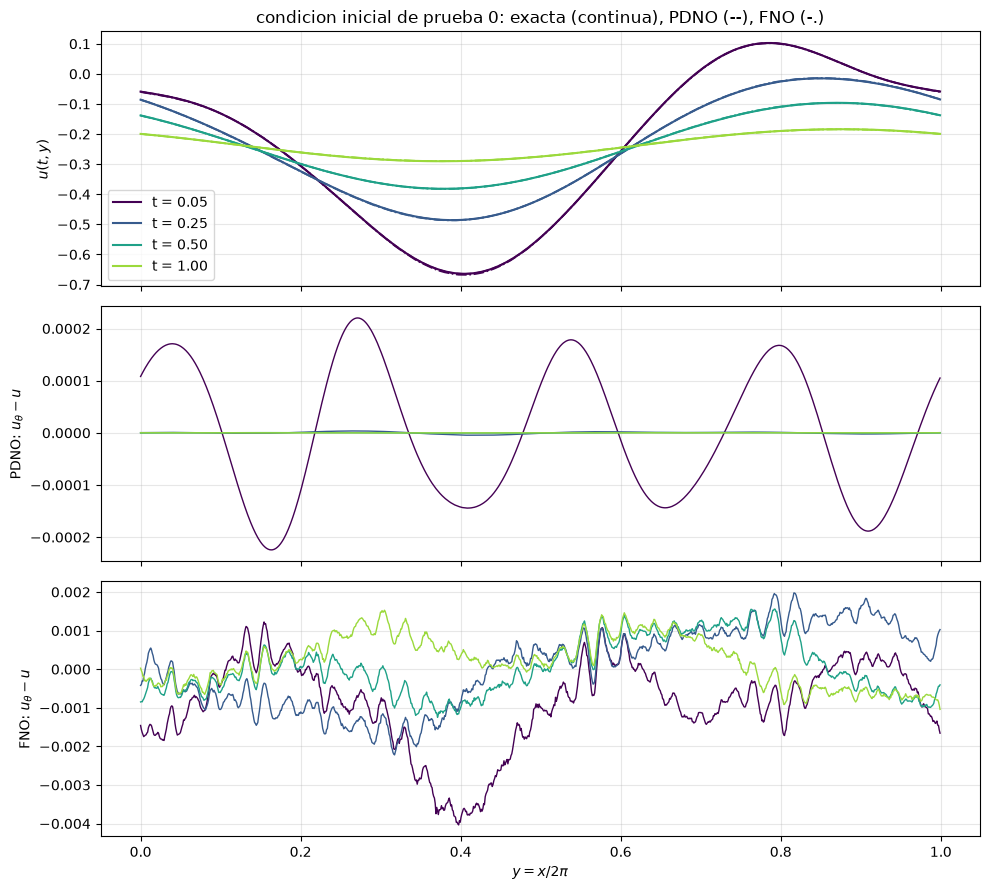

In [14]:
i = 0
idx_t = [0, 4, 9, 19]                                  # t = 0.05, 0.25, 0.5, 1.0
colores = plt.cm.viridis(np.linspace(0, 0.85, len(idx_t)))
exacta = ds.test.u[i, idx_t].numpy()
pred = {}
with torch.no_grad():
    for nombre, m in models.items():
        u0_rep = ds.test.u0[i].to(m.device, m.dtype).repeat(len(idx_t), 1)
        pred[nombre] = m(u0_rep, ds.test.t[idx_t].to(m.device, m.dtype)).cpu().numpy()

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
estilos = {"PDNO": "--", "FNO": "-."}
for j, color in enumerate(colores):
    axes[0].plot(y, exacta[j], "-", color=color, lw=1.5, label=f"t = {float(ds.test.t[idx_t[j]]):.2f}")
    for fila, nombre in enumerate(models, start=1):
        axes[0].plot(y, pred[nombre][j], estilos[nombre], color=color, lw=1.2)
        axes[fila].plot(y, pred[nombre][j] - exacta[j], "-", color=color, lw=1)
axes[0].set_ylabel(r"$u(t, y)$")
axes[0].set_title(f"condicion inicial de prueba {ds.test.ic[i]}: exacta (continua), PDNO (--), FNO (-.)")
axes[0].legend()
for fila, nombre in enumerate(models, start=1):
    axes[fila].set_ylabel(rf"{nombre}: $u_\theta - u$")
axes[-1].set_xlabel(r"$y = x / 2\pi$")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(RESULTS / "campo.png", dpi=150)
plt.show()

## 6. Extrapolacion temporal

Las $u_0$ de prueba en `EXTRAPOLATION_TIMES` $\subset(0.95,3]$, fuera del rango de entrenamiento. Solo se reporta: no
interviene en el entrenamiento ni en la seleccion. Para $t$ grande la solucion es casi su media ($a(0)=0$) mas los modos
$|k|=1$, asi que el error relativo mide sobre todo si el modelo conserva la media y amortigua el resto.

EXTRAPOLACION -- 20 condiciones iniciales x 21 tiempos en [1, 3]
  PDNO: error relativo L2 = 1.7112e-07  (medio; max 1.5331e-06)
  FNO: error relativo L2 = 1.7941e-01  (medio; max 1.6819e+00)


PDNO                     FNO                           
               media           max     media       max en_entrenamiento
t                                                                      
1.00    3.816281e-07  1.533108e-06  0.026576  0.063542            False
1.10    3.522895e-07  1.467542e-06  0.029956  0.076536            False
1.20    3.125230e-07  1.361666e-06  0.036173  0.104494            False
1.30    3.216952e-07  1.431802e-06  0.045886  0.151144            False
1.40    2.787532e-07  1.243468e-06  0.058724  0.213807            False
1.50    2.417507e-07  1.070525e-06  0.073999  0.288189            False
1.60    2.228942e-07  9.976970e-07  0.091077  0.370723            False
1.70    1.925418e-07  8.512415e-07  0.109437  0.458558            False
1.80    1.751854e-07  7.691290e-07  0.128714  0.549752            False
1.90    1.594350e-07  6.866840e-07  0.148629  0.642901            False
2.00    1.369804e-07  5.777235e-07  0.168988  0.737072            False
2.10    1.226274e-07  4.981135e-07  0.189660  0.831712            False
2.20    1.076003e-07  4.267473e-07  0.210552  0.926445            False
2.30    1.012953e-07  3.999236e-07  0.231586  1.020890            False
2.40    8.447690e-08  3.028578e-07  0.252726  1.114959            False
2.50    7.970201e-08  2.744328e-07  0.273946  1.208544            False
2.60    7.624354e-08  2.548507e-07  0.295243  1.301732            False
2.70    6.657797e-08  1.986132e-07  0.316616  1.394450            False
2.80    6.409956e-08  1.858509e-07  0.338088  1.489926            False
2.90    5.992346e-08  1.564156e-07  0.359666  1.585850            False
3.00    5.522646e-08  1.328892e-07  0.381390  1.681930            False
global  1.711166e-07  1.533108e-06  0.179411  1.681930             None

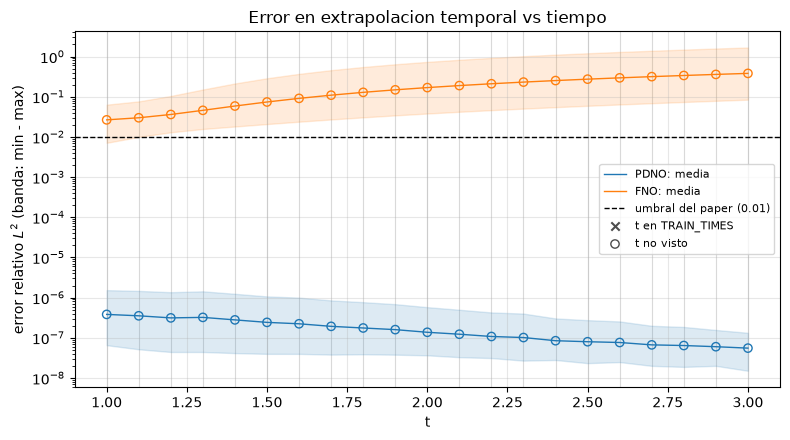

In [15]:
t_ext = ds.extrapolation.t.numpy()
err_ext = {nombre: field_errors(m, ds.extrapolation) for nombre, m in models.items()}
print(f"EXTRAPOLACION -- {ds.extrapolation.n_ic} condiciones iniciales x {ds.extrapolation.n_times} tiempos "
      f"en [{t_ext.min():g}, {t_ext.max():g}]")
for nombre, err in err_ext.items():
    print(f"  {nombre}: error relativo L2 = {err.mean():.4e}  (medio; max {err.max():.4e})")

tabla_ext = error_table(err_ext, t_ext)
tabla_ext.to_csv(RESULTS / "extrapolacion.csv")
display(tabla_ext)

error_figure(err_ext, t_ext, "Error en extrapolacion temporal vs tiempo", "error_extrapolacion.png")

## 8. Invariancia de resolucion

Los dos modelos, entrenados en $1024$, evaluados sobre las mismas $20$ $u_0$ de prueba en `TEST_TIMES` en otras mallas
(`resample_fields`, a partir de los campos exactos en float64 y luego a float32):

- **$256$ y $512$:** submuestreo de los campos exactos (los valores de las mismas funciones en la malla gruesa). Los
  modos por encima del Nyquist grueso se pliegan (aliasing), pero con el decaimiento del GRF son despreciables.
- **$2048$:** relleno con ceros del espectro de $\hat u_0$ y de $\hat u(t)$. Como $e^{-ta(D)}$ es diagonal y los modos
  nuevos valen $0$, es la solucion exacta de la misma $u_0$ en una malla mas fina. La celda comprueba que submuestrear
  los campos de $2048$ devuelve los de $1024$.

El PDNO evalua su simbolo en los modos de cada malla; el FNO usa los mismos `n_modes` y recalcula el embedding de
posicion.

,PDNO media,PDNO max,FNO media,FNO max
resolucion,,,,
256,0.000031,0.000909,0.019625,0.065047
512,0.000030,0.000908,0.004395,0.024577
1024,0.000030,0.000909,0.019630,0.065025
2048,0.000030,0.000909,0.019632,0.065032


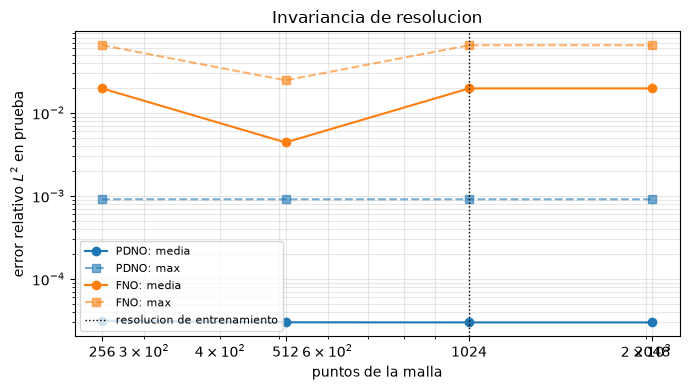

In [17]:
fino = resample_fields(ds64.test, 2 * RESOLUTION)
assert torch.allclose(resample_fields(fino, RESOLUTION).u, ds64.test.u, rtol=0, atol=1e-12)

filas = []
err_res = {}
for R in EVAL_RESOLUTIONS:
    test_R = resample_fields(ds64.test, R).to("cpu", DTYPE)
    fila = {"resolucion": R}
    for nombre, m in models.items():
        err = field_errors(m, test_R)
        err_res[(nombre, R)] = err
        fila[f"{nombre} media"] = err.mean()
        fila[f"{nombre} max"] = err.max()
    filas.append(fila)
resolucion = pd.DataFrame(filas).set_index("resolucion")
resolucion.to_csv(RESULTS / "resolucion.csv")
display(resolucion)

fig, ax = plt.subplots(figsize=(7, 4))
for nombre in models:
    ax.loglog(EVAL_RESOLUTIONS, resolucion[f"{nombre} media"], "o-", color=colores_modelo[nombre],
              label=f"{nombre}: media")
    ax.loglog(EVAL_RESOLUTIONS, resolucion[f"{nombre} max"], "s--", color=colores_modelo[nombre], alpha=0.6,
              label=f"{nombre}: max")
ax.axvline(RESOLUTION, color="k", ls=":", lw=1, label="resolucion de entrenamiento")
ax.set_xticks(EVAL_RESOLUTIONS)
ax.set_xticklabels([str(R) for R in EVAL_RESOLUTIONS])
ax.set_xlabel("puntos de la malla")
ax.set_ylabel(r"error relativo $L^2$ en prueba")
ax.set_title("Invariancia de resolucion")
ax.legend(fontsize=8)
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
fig.savefig(RESULTS / "resolucion.png", dpi=150)
plt.show()

## 9. Simbolo y certificacion del PDNO

**Simbolo efectivo.** $\bar a(k)$ (`effective_symbol`) frente a $4\pi^2\cdot0.05\,|k|^2$ en todos los modos de la malla,
$|k|\le512$. La zona sombreada es la ventana de entrenamiento $|k|\le k_{\max}=64$. A la derecha, $\bar a(k)/\langle k\rangle^m$
esta siempre en la banda $(c,C)$ por construccion.

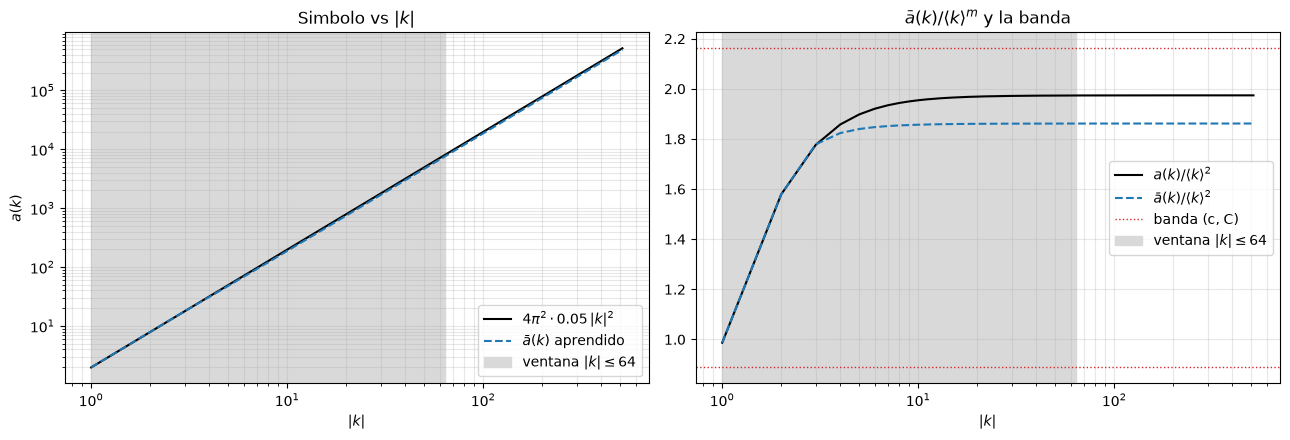

In [18]:
k_sym = k_grid(1, RESOLUTION // 2)
a_eff = np.real(efectivo.evaluate_batch(k_sym))
a_ref = symbol_values(REFERENCE, k_sym)
abs_k = np.abs(k_sym[:, 0])
dentro = abs_k <= k_max
positivo = k_sym[:, 0] > 0
orden = np.argsort(k_sym[positivo, 0])
kk = k_sym[positivo, 0][orden]
etiqueta_ref = r"$4\pi^2 \cdot 0.05\,|k|^2$"

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].loglog(kk, a_ref[positivo][orden], "k-", lw=1.5, label=etiqueta_ref)
axes[0].loglog(kk, a_eff[positivo][orden], "--", color="C0", lw=1.5, label=r"$\bar a(k)$ aprendido")
axes[0].set_ylabel(r"$a(k)$")
axes[0].set_title(r"Simbolo vs $|k|$")

h_eff = a_eff / (1.0 + k_sym[:, 0] ** 2) ** (M / 2)
h_ref = a_ref / (1.0 + k_sym[:, 0] ** 2) ** (M / 2)
axes[1].semilogx(kk, h_ref[positivo][orden], "k-", lw=1.5, label=r"$a(k) / \langle k\rangle^2$")
axes[1].semilogx(kk, h_eff[positivo][orden], "--", color="C0", lw=1.5, label=r"$\bar a(k) / \langle k\rangle^2$")
axes[1].axhline(bounds.c, color="C3", ls=":", lw=1, label="banda (c, C)")
axes[1].axhline(bounds.C, color="C3", ls=":", lw=1)
axes[1].set_title(r"$\bar a(k) / \langle k\rangle^m$ y la banda")
for ax in axes:
    ax.axvspan(1, k_max, color="0.85", zorder=0, label=rf"ventana $|k| \leq {k_max}$")
    ax.set_xlabel(r"$|k|$")
    ax.grid(alpha=0.3, which="both")
    ax.legend()
plt.tight_layout()
fig.savefig(RESULTS / "simbolo.png", dpi=150)
plt.show()

**Error del simbolo.** $|\bar a(k)-a(k)|/|a(k)|$ en cada $|k|$ ($k=0$ se omite: ahi ambos valen $0$), dentro y fuera de la
ventana. Fuera de ella el multiplicador $e^{-t\,a(k)}$ es practicamente $0$ para casi todos los $t$, asi que los datos casi
no informan sobre $\bar a$ y solo la banda lo restringe.

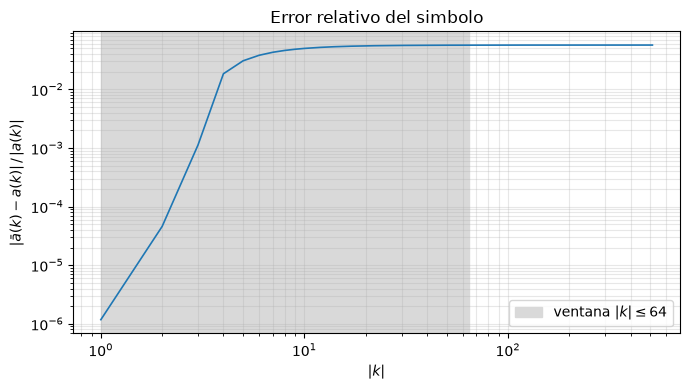

,dentro (|k| <= 64),fuera (|k| > 64)
n,129.000000,8.960000e+02
mse,43284.423437,1.993715e+08
rmse,208.049089,1.411990e+04
mae,154.510702,1.123372e+04
max_error,458.973382,2.946333e+04
rel_l2,0.056656,5.693754e-02
error_relativo_medio,0.051468,5.692041e-02
error_relativo_max,0.056767,5.693932e-02


In [19]:
rel = relative_symbol_error(a_eff, a_ref)

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(kk, rel[positivo][orden], "-", color="C0", lw=1.2)
ax.axvspan(1, k_max, color="0.85", zorder=0, label=rf"ventana $|k| \leq {k_max}$")
ax.set_xlabel(r"$|k|$")
ax.set_ylabel(r"$|\bar a(k) - a(k)| \,/\, |a(k)|$")
ax.set_title("Error relativo del simbolo")
ax.legend()
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
fig.savefig(RESULTS / "error_simbolo.png", dpi=150)
plt.show()

no_cero = abs_k > 0
metricas = {}
for nombre, region in (("dentro (|k| <= %d)" % k_max, dentro), ("fuera (|k| > %d)" % k_max, ~dentro)):
    reporte = symbol_report(efectivo, REFERENCE, k_sym[region])
    reporte["error_relativo_medio"] = float(rel[region & no_cero].mean())
    reporte["error_relativo_max"] = float(rel[region & no_cero].max())
    metricas[nombre] = reporte
metricas_simbolo = pd.DataFrame(metricas)
metricas_simbolo.to_csv(RESULTS / "metricas_simbolo.csv")
display(metricas_simbolo)

**Parabolicidad (Def. 2.3).** `ParabolicityVerifier` sobre el simbolo de cada capa y sobre el efectivo, con $k$ en
$|k|\le K$ para $K\in\{k_{\max},2k_{\max},3k_{\max}\}$ y `CERT_LAM`. El peor ratio es $\hat\kappa/\kappa$; se cumple si es $\le1$.

**Clase $S^{m,\rho}$ (Def. 2.1).** `SymbolClassVerifier` en ventanas crecientes, como en 06. Es evidencia en una ventana
finita, no una prueba sobre todo $\mathbb Z^n$. El simbolo se evalua en float32, asi que las diferencias finitas
incluyen el redondeo de float32.

In [20]:
kappa = model_pdno.theoretical_kappa(OMEGA)
cert_k_max = 3 * k_max
simbolos = {f"capa {l}": s for l, s in enumerate(model_pdno.symbols)}
simbolos["efectivo"] = efectivo

filas = []
for nombre, simbolo in simbolos.items():
    verifier = ParabolicityVerifier(simbolo)
    for window in (k_max, 2 * k_max, cert_k_max):
        k_values = k_grid(1, window)
        ratio = verifier.estimate_kappa_batch(k_values, CERT_LAM, omega=OMEGA) / kappa
        filas.append({
            "simbolo": nombre, "K": window, "region": "dentro" if window <= k_max else "fuera",
            "puntos": len(k_values) * len(CERT_LAM), "max_ratio": ratio, "satisfecha": ratio <= 1.0,
        })
certificacion = pd.DataFrame(filas)
certificacion.to_csv(RESULTS / "certificacion.csv", index=False)
print(f"kappa usada = {kappa:.4f}")
display(certificacion)

kappa usada = 2.0000


,simbolo,K,region,puntos,max_ratio,satisfecha
0,capa 0,64,dentro,80625,0.912702,True
1,capa 0,128,fuera,160625,0.912702,True
2,capa 0,192,fuera,240625,0.912702,True
3,efectivo,64,dentro,80625,0.912702,True
4,efectivo,128,fuera,160625,0.912702,True
5,efectivo,192,fuera,240625,0.912702,True


In [21]:
class_k_maxs = (4, 8, 12, 2 * k_max)
filas = []
for nombre, simbolo in simbolos.items():
    for r in SymbolClassVerifier(simbolo).check(k_maxs=class_k_maxs):
        filas.append({
            "simbolo": nombre,
            "alpha": str(r.alpha),
            "|alpha|": r.order,
            **{f"C_hat({K})": r.c_hat[K] for K in class_k_maxs},
            f"crecim.({class_k_maxs[-2]}->{class_k_maxs[-1]})": r.growth,
            "pendiente": r.slope,
            "m-|alpha|": r.slope_theoretical,
            "estable": r.stable,
            "consistente": r.consistent,
        })
clase = pd.DataFrame(filas)
clase.to_csv(RESULTS / "clase.csv", index=False)
display(clase)

for nombre, grupo in clase.groupby("simbolo", sort=False):
    print(f"{nombre}: consistentes {int(grupo['consistente'].sum())} de {len(grupo)} multiindices")
print(f"ventana explorada: |k| <= {class_k_maxs[-1]} (evidencia, no prueba sobre todo Z^n)")
print("pendiente = nan significa Delta^alpha a = 0 en la ventana, asi que C_alpha = 0 basta")

,simbolo,alpha,|alpha|,C_hat(4),C_hat(8),C_hat(12),C_hat(128),crecim.(12->128),pendiente,m-|alpha|,estable,consistente
0,capa 0,"(0,)",0,1.823542,1.853959,1.858304,1.861495,1.001717,2.000060,2.0,True,True
1,capa 0,"(1,)",1,4.422890,4.422890,4.422890,4.422890,1.000000,0.994642,1.0,True,True
2,capa 0,"(2,)",2,3.968479,3.968479,3.968479,3.968479,1.000000,0.000483,0.0,True,True
3,efectivo,"(0,)",0,1.823542,1.853959,1.858304,1.861495,1.001717,2.000060,2.0,True,True
4,efectivo,"(1,)",1,4.422890,4.422890,4.422890,4.422890,1.000000,0.994642,1.0,True,True
5,efectivo,"(2,)",2,3.968479,3.968479,3.968479,3.968479,1.000000,0.000483,0.0,True,True


capa 0: consistentes 3 de 3 multiindices
efectivo: consistentes 3 de 3 multiindices
ventana explorada: |k| <= 128 (evidencia, no prueba sobre todo Z^n)
pendiente = nan significa Delta^alpha a = 0 en la ventana, asi que C_alpha = 0 basta


## 11. Modelos guardados

- `modelo_pdno.pt` (`save_operator_model`): la corrida elegida del PDNO, con su `PDNOConfig`, su
  `OperatorTrainingConfig`, las $C_\alpha$ usadas y lo necesario para regenerar los datos, incluidos `diffusivity`,
  `freq_scale` y `amplitude`.
- `modelo_fno.pt` (`save_fno_model`): la corrida elegida del FNO, con su `FNOConfig`, la version de `neuraloperator`, su
  `OperatorTrainingConfig` y la misma entrada de datos.

In [ ]:
datos_guardados = dict(
    reference=REFERENCE, resolution=RESOLUTION, k_cap=K_CAP, seed=SEED, val_fraction=VAL_FRACTION,
    extrapolation_times=EXTRAPOLATION_TIMES, freq_scale=FREQ_SCALE, amplitude=AMPLITUDE,
)
save_operator_model(
    RESULTS / "modelo_pdno.pt", model_pdno, config=best_pdno.config, result=result_pdno,
    delta=DELTA, estimate_tol=ESTIMATE_TOL, **datos_guardados,
)
save_fno_model(RESULTS / "modelo_fno.pt", model_fno, config=best_fno.config, result=result_fno, **datos_guardados)

In [ ]:
cargados = {
    "PDNO": load_operator_model(RESULTS / "modelo_pdno.pt", device=DEVICE),
    "FNO": load_fno_model(RESULTS / "modelo_fno.pt", device=DEVICE),
}
for nombre, cargado in cargados.items():
    err_cargado = field_errors(cargado, ds.test)
    print(f"{nombre}: error de prueba (cargado) = {err_cargado.mean():.6e}  |  "
          f"(entrenado) = {err_test[nombre].mean():.6e}  |  identicos: {np.array_equal(err_cargado, err_test[nombre])}")